In [ ]:
from google.colab import drive
import os
mount_path='/content/drive'
os.makedirs(mount_path,exist_ok=True)
drive.mount(mount_path)
print("Google Drive connected successfully")

Mounted at /content/drive
Google Drive connected successfully


In [ ]:
!pip -q install rasterio scipy

import os
import glob
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from scipy import stats

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Find the exported satellite file in Google Drive

files = glob.glob(
    '/content/drive/MyDrive/**/Indore_Heat_Analysis_2025.tif',
    recursive=True
)

if len(files) == 0:
    raise FileNotFoundError(
        "TIFF file not found. Check your Google Drive folder."
    )

tiff_path = files[0]

print("Satellite file found:")
print(tiff_path)

Satellite file found:
/content/drive/MyDrive/Urban_Heat_Mapping_Project/01_Data/Indore_Heat_Analysis_2025.tif


In [ ]:
# Read satellite raster

with rasterio.open(tiff_path) as src:

    print("Number of bands:", src.count)
    print("Image dimensions:", src.width, "x", src.height)
    print("Coordinate Reference System:", src.crs)
    print("Resolution:", src.res)
    print("Band descriptions:", src.descriptions)

    # Band 1 = Land Surface Temperature
    lst_data = src.read(1, masked=True)

    # Band 2 = NDVI
    ndvi_data = src.read(2, masked=True)

print("\nSatellite data loaded successfully!")

print("LST shape:", lst_data.shape)
print("NDVI shape:", ndvi_data.shape)

Number of bands: 2
Image dimensions: 1080 x 1003
Coordinate Reference System: EPSG:4326
Resolution: (0.00026949458523585647, 0.00026949458523585647)
Band descriptions: ('LST_Celsius', 'NDVI')

Satellite data loaded successfully!
LST shape: (1003, 1080)
NDVI shape: (1003, 1080)


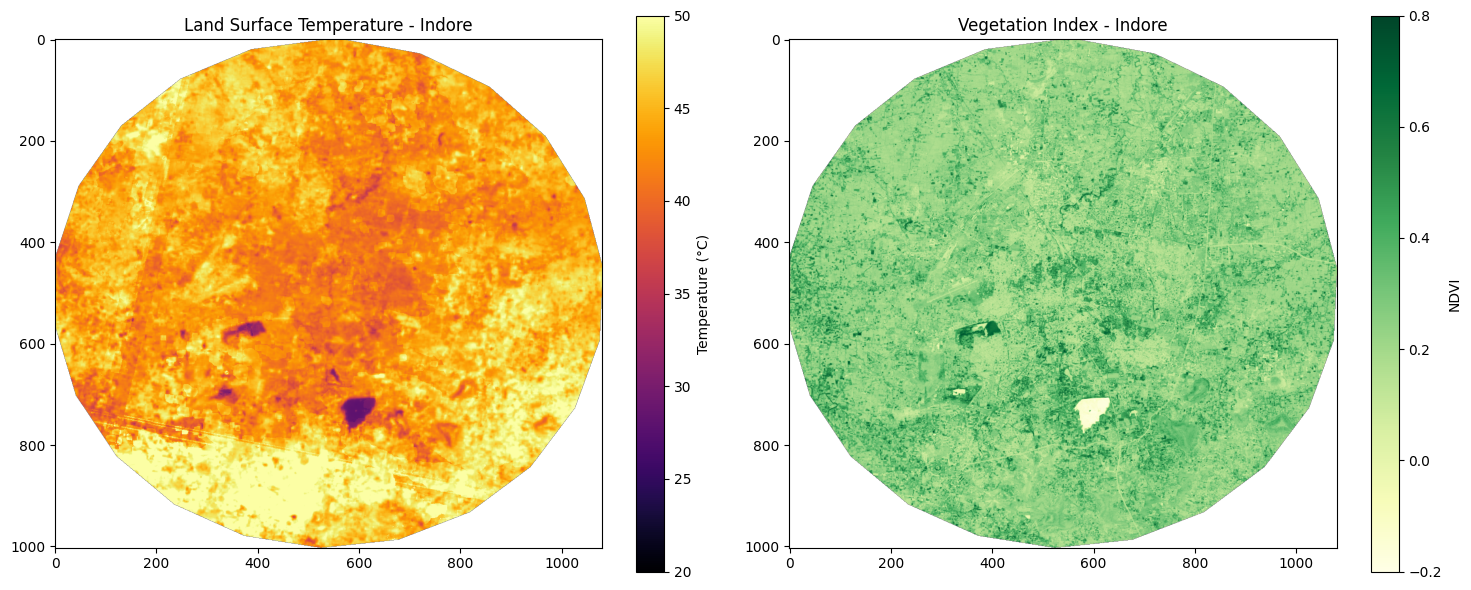

In [ ]:
# Convert masked arrays for plotting

lst_plot = np.ma.masked_invalid(lst_data)
ndvi_plot = np.ma.masked_invalid(ndvi_data)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Temperature map
im1 = axes[0].imshow(
    lst_plot,
    cmap='inferno',
    vmin=20,
    vmax=50
)

axes[0].set_title('Land Surface Temperature - Indore')
plt.colorbar(im1, ax=axes[0], label='Temperature (°C)')

# Vegetation map
im2 = axes[1].imshow(
    ndvi_plot,
    cmap='YlGn',
    vmin=-0.2,
    vmax=0.8
)

axes[1].set_title('Vegetation Index - Indore')
plt.colorbar(im2, ax=axes[1], label='NDVI')

plt.tight_layout()
plt.show()

In [ ]:
# STEP 5.1: Temperature statistical analysis

# Extract valid temperature values
lst_values = lst_data.compressed()

# Remove non-finite values
lst_values = lst_values[np.isfinite(lst_values)]

# Calculate temperature statistics
temperature_stats = {
    'Mean Temperature (°C)': np.mean(lst_values),
    'Median Temperature (°C)': np.median(lst_values),
    'Minimum Temperature (°C)': np.min(lst_values),
    'Maximum Temperature (°C)': np.max(lst_values),
    'Standard Deviation (°C)': np.std(lst_values),
    '90th Percentile (°C)': np.percentile(lst_values, 90),
    '95th Percentile (°C)': np.percentile(lst_values, 95)
}

print("INDORE LAND SURFACE TEMPERATURE STATISTICS")
print("-------------------------------------------")

for metric, value in temperature_stats.items():
    print(f"{metric}: {value:.2f}")

print("\nTotal valid pixels:", len(lst_values))

INDORE LAND SURFACE TEMPERATURE STATISTICS
-------------------------------------------
Mean Temperature (°C): 44.44
Median Temperature (°C): 44.26
Minimum Temperature (°C): 27.96
Maximum Temperature (°C): 57.50
Standard Deviation (°C): 3.23
90th Percentile (°C): 48.63
95th Percentile (°C): 50.03

Total valid pixels: 845072


In [ ]:
# STEP 5.2: Identify relative heat hotspots

# Calculate the 90th percentile threshold
hotspot_threshold = np.percentile(lst_values, 90)

# Create hotspot mask
hotspot_mask = (
    (lst_data >= hotspot_threshold) &
    (~np.ma.getmaskarray(lst_data))
)

# Calculate percentage of hotspot pixels
total_valid_pixels = np.ma.count(lst_data)
hotspot_pixels = np.count_nonzero(hotspot_mask)

hotspot_percentage = (
    hotspot_pixels / total_valid_pixels
) * 100

print("RELATIVE HEAT HOTSPOT ANALYSIS")
print("--------------------------------")

print(f"Hotspot threshold: {hotspot_threshold:.2f} °C")
print("Hotspot pixels:", hotspot_pixels)
print("Total valid pixels:", total_valid_pixels)
print(f"Hotspot coverage: {hotspot_percentage:.2f}%")

RELATIVE HEAT HOTSPOT ANALYSIS
--------------------------------
Hotspot threshold: 48.63 °C
Hotspot pixels: 84540
Total valid pixels: 1083240
Hotspot coverage: 7.80%


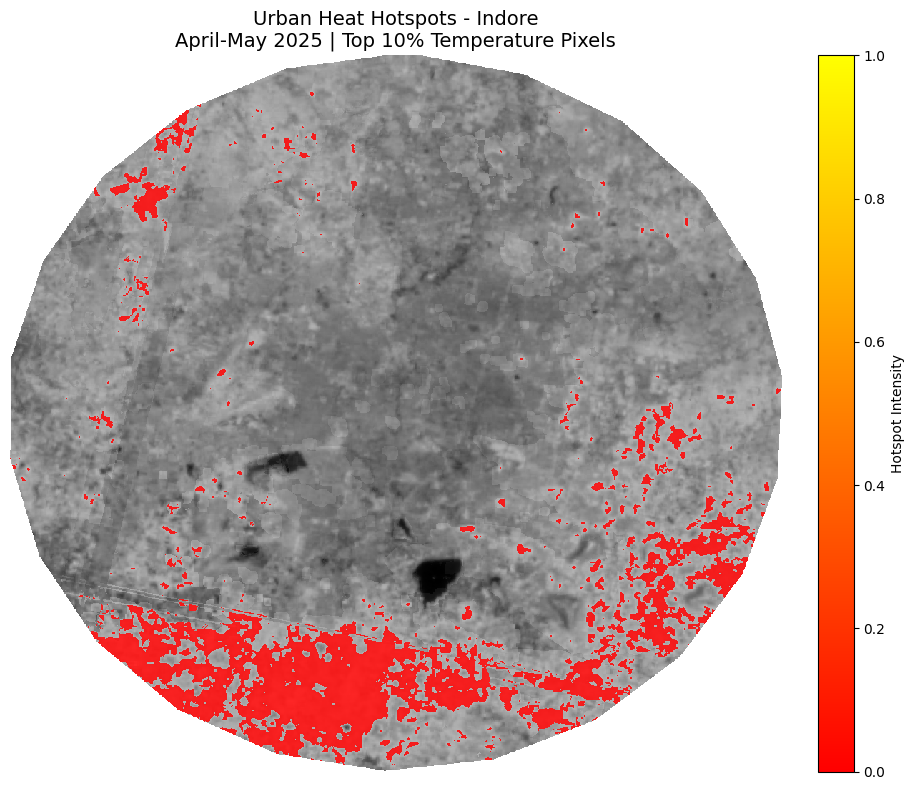

In [ ]:
# STEP 5.3: Heat hotspot visualisation

fig, ax = plt.subplots(figsize=(10, 8))

# Background LST image
ax.imshow(
    lst_data,
    cmap='gray',
    interpolation='nearest'
)

# Hotspot overlay
ax.imshow(
    np.ma.masked_where(~hotspot_mask, hotspot_mask),
    cmap='autumn',
    interpolation='nearest',
    alpha=0.85
)

ax.set_title(
    'Urban Heat Hotspots - Indore\n'
    'April-May 2025 | Top 10% Temperature Pixels',
    fontsize=14
)

ax.axis('off')

# Create colorbar
sm = plt.cm.ScalarMappable(
    cmap='autumn',
    norm=plt.Normalize(vmin=0, vmax=1)
)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label('Hotspot Intensity')

plt.tight_layout()
plt.show()

In [ ]:
# STEP 5.4: Hotspot coverage summary

normal_pixels = total_valid_pixels - hotspot_pixels

coverage_summary = pd.DataFrame({
    'Category': ['Relative Hotspots', 'Other Areas'],
    'Pixel Count': [hotspot_pixels, normal_pixels],
    'Percentage': [
        hotspot_percentage,
        100 - hotspot_percentage
    ]
})

print(coverage_summary.to_string(index=False))

         Category  Pixel Count  Percentage
Relative Hotspots        84540    7.804365
      Other Areas       998700   92.195635


In [ ]:
# STEP 5.5: Save temperature statistics

output_folder = (
    '/content/drive/MyDrive/'
    'Urban_Heat_Mapping_Project/04_Reports'
)

os.makedirs(output_folder, exist_ok=True)

stats_df = pd.DataFrame(
    list(temperature_stats.items()),
    columns=['Metric', 'Value']
)

stats_df.to_csv(
    os.path.join(output_folder, 'temperature_statistics.csv'),
    index=False
)

coverage_summary.to_csv(
    os.path.join(output_folder, 'hotspot_coverage.csv'),
    index=False
)

print("Statistical results saved successfully!")

Statistical results saved successfully!


CORRECTED HOTSPOT ANALYSIS
--------------------------
Valid pixels: 845072
Hotspot pixels: 84540
90th percentile: 48.63 °C
Hotspot coverage: 10.00%


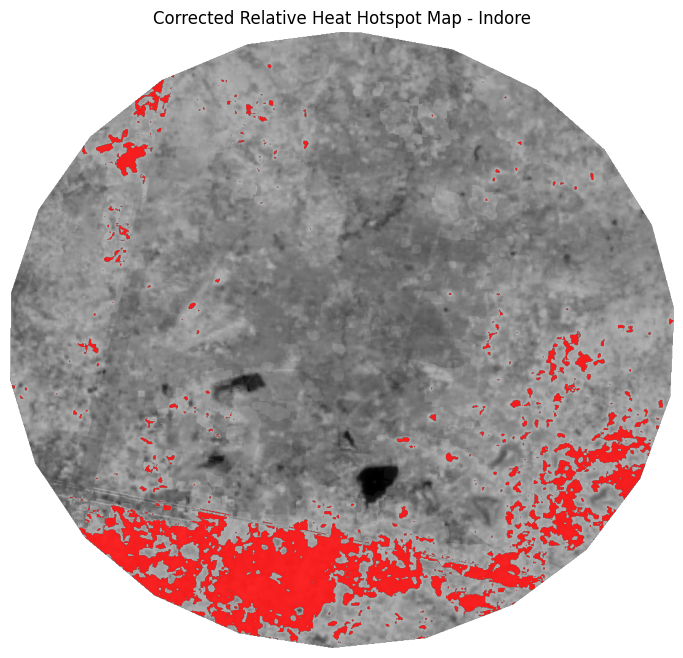

In [ ]:
# STEP 5 CORRECTION: Robust hotspot calculation

# Convert masked arrays to NumPy arrays with NaN for invalid pixels

lst_array = np.asarray(
    np.ma.filled(lst_data, np.nan),
    dtype=float
)

ndvi_array = np.asarray(
    np.ma.filled(ndvi_data, np.nan),
    dtype=float
)

# Identify valid temperature pixels

valid_lst = np.isfinite(lst_array)

# Recalculate threshold

hotspot_threshold = np.nanpercentile(
    lst_array,
    90
)

# Identify hotspot pixels

hotspot_mask = (
    valid_lst &
    (lst_array >= hotspot_threshold)
)

total_valid_pixels = np.count_nonzero(valid_lst)
hotspot_pixels = np.count_nonzero(hotspot_mask)

hotspot_percentage = (
    hotspot_pixels / total_valid_pixels
) * 100

print("CORRECTED HOTSPOT ANALYSIS")
print("--------------------------")
print("Valid pixels:", total_valid_pixels)
print("Hotspot pixels:", hotspot_pixels)
print(f"90th percentile: {hotspot_threshold:.2f} °C")
print(f"Hotspot coverage: {hotspot_percentage:.2f}%")

# Display corrected map

plt.figure(figsize=(10, 8))

plt.imshow(
    np.where(valid_lst, lst_array, np.nan),
    cmap='gray'
)

plt.imshow(
    np.where(hotspot_mask, 1, np.nan),
    cmap='autumn',
    alpha=0.85
)

plt.title('Corrected Relative Heat Hotspot Map - Indore')
plt.axis('off')
plt.show()

In [ ]:
# STEP 6.1: Prepare paired satellite observations

valid_pixels = (
    np.isfinite(lst_array) &
    np.isfinite(ndvi_array)
)

lst_valid = lst_array[valid_pixels]
ndvi_valid = ndvi_array[valid_pixels]

print("Paired valid pixels:", len(lst_valid))
print("Temperature observations:", len(lst_valid))
print("NDVI observations:", len(ndvi_valid))

Paired valid pixels: 845072
Temperature observations: 845072
NDVI observations: 845072


In [ ]:
# STEP 6.2: Pearson correlation

correlation, p_value = stats.pearsonr(
    lst_valid,
    ndvi_valid
)

print("VEGETATION-TEMPERATURE CORRELATION")
print("----------------------------------")

print(f"Pearson correlation: {correlation:.4f}")
print(f"P-value: {p_value:.6f}")

if correlation < 0:
    print("Observed relationship: Negative")
elif correlation > 0:
    print("Observed relationship: Positive")
else:
    print("Observed relationship: No linear association")

VEGETATION-TEMPERATURE CORRELATION
----------------------------------
Pearson correlation: -0.1910
P-value: 0.000000
Observed relationship: Negative


In [ ]:
# STEP 6.3: Compare vegetation in hotspot areas

paired_hotspots = (
    valid_pixels &
    hotspot_mask
)

paired_non_hotspots = (
    valid_pixels &
    (~hotspot_mask)
)

hotspot_ndvi = ndvi_array[paired_hotspots]
non_hotspot_ndvi = ndvi_array[paired_non_hotspots]

print("VEGETATION COMPARISON")
print("---------------------")

print(
    "Mean NDVI in hotspots:",
    round(np.mean(hotspot_ndvi), 4)
)

print(
    "Mean NDVI outside hotspots:",
    round(np.mean(non_hotspot_ndvi), 4)
)

print(
    "Difference:",
    round(
        np.mean(non_hotspot_ndvi) -
        np.mean(hotspot_ndvi),
        4
    )
)

VEGETATION COMPARISON
---------------------
Mean NDVI in hotspots: 0.2408
Mean NDVI outside hotspots: 0.2663
Difference: 0.0256


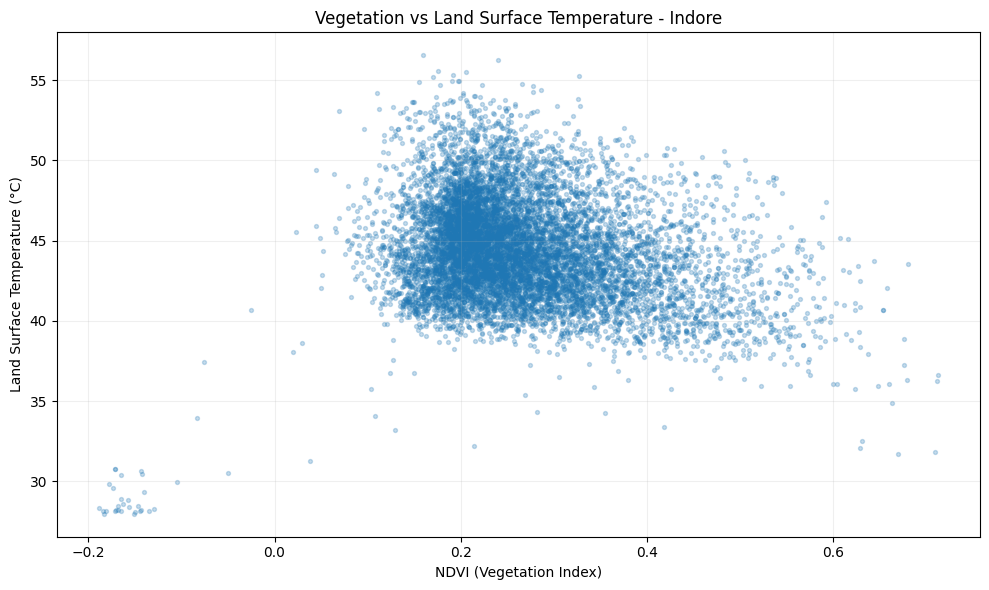

In [ ]:
# STEP 6.4: Vegetation vs temperature scatter plot

# Sample up to 10,000 pixels for visualisation

rng = np.random.default_rng(42)

sample_size = min(10000, len(lst_valid))

sample_indices = rng.choice(
    len(lst_valid),
    size=sample_size,
    replace=False
)

plt.figure(figsize=(10, 6))

plt.scatter(
    ndvi_valid[sample_indices],
    lst_valid[sample_indices],
    alpha=0.25,
    s=8
)

plt.xlabel('NDVI (Vegetation Index)')
plt.ylabel('Land Surface Temperature (°C)')

plt.title(
    'Vegetation vs Land Surface Temperature - Indore'
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [ ]:
# STEP 6.5: Save vegetation analysis results

vegetation_results = pd.DataFrame({
    'Metric': [
        'Pearson Correlation',
        'P-value',
        'Mean NDVI in Hotspots',
        'Mean NDVI Outside Hotspots',
        'Valid Paired Pixels'
    ],
    'Value': [
        correlation,
        p_value,
        np.mean(hotspot_ndvi),
        np.mean(non_hotspot_ndvi),
        len(lst_valid)
    ]
})

vegetation_results.to_csv(
    os.path.join(
        output_folder,
        'vegetation_temperature_analysis.csv'
    ),
    index=False
)

print("Vegetation analysis results saved!")

Vegetation analysis results saved!


In [ ]:
# STEP 7.1: Urban heat priority classification

# Use pixels where both variables are valid
valid = (
    np.isfinite(lst_array) &
    np.isfinite(ndvi_array)
)

# Calculate percentile thresholds
high_temp_threshold = np.nanpercentile(
    lst_array[valid], 90
)

low_vegetation_threshold = np.nanpercentile(
    ndvi_array[valid], 10
)

print("HIGH TEMPERATURE THRESHOLD:",
      round(high_temp_threshold, 2), "°C")

print("LOW VEGETATION THRESHOLD:",
      round(low_vegetation_threshold, 4))

# Define conditions
high_temp = (
    valid &
    (lst_array >= high_temp_threshold)
)

low_vegetation = (
    valid &
    (ndvi_array <= low_vegetation_threshold)
)

# Assign scores:
# 0 = Lower priority
# 1 = Moderate priority
# 2 = High priority

priority_map = np.full(
    lst_array.shape,
    -9999,
    dtype=np.int16
)

priority_map[valid] = 0

priority_map[valid & (high_temp | low_vegetation)] = 1

priority_map[high_temp & low_vegetation] = 2

print("\nPriority classification completed!")

HIGH TEMPERATURE THRESHOLD: 48.63 °C
LOW VEGETATION THRESHOLD: 0.1714

Priority classification completed!


In [ ]:
# STEP 7.2: Priority distribution

priority_counts = {
    "Lower Priority": np.count_nonzero(
        priority_map == 0
    ),
    "Moderate Priority": np.count_nonzero(
        priority_map == 1
    ),
    "High Priority": np.count_nonzero(
        priority_map == 2
    )
}

total_pixels = np.count_nonzero(valid)

priority_summary = pd.DataFrame([
    {
        "Priority": category,
        "Pixel Count": count,
        "Percentage": count / total_pixels * 100
    }
    for category, count in priority_counts.items()
])

print(priority_summary.to_string(index=False))

         Priority  Pixel Count  Percentage
   Lower Priority       685258   81.088712
Moderate Priority       150580   17.818600
    High Priority         9234    1.092688


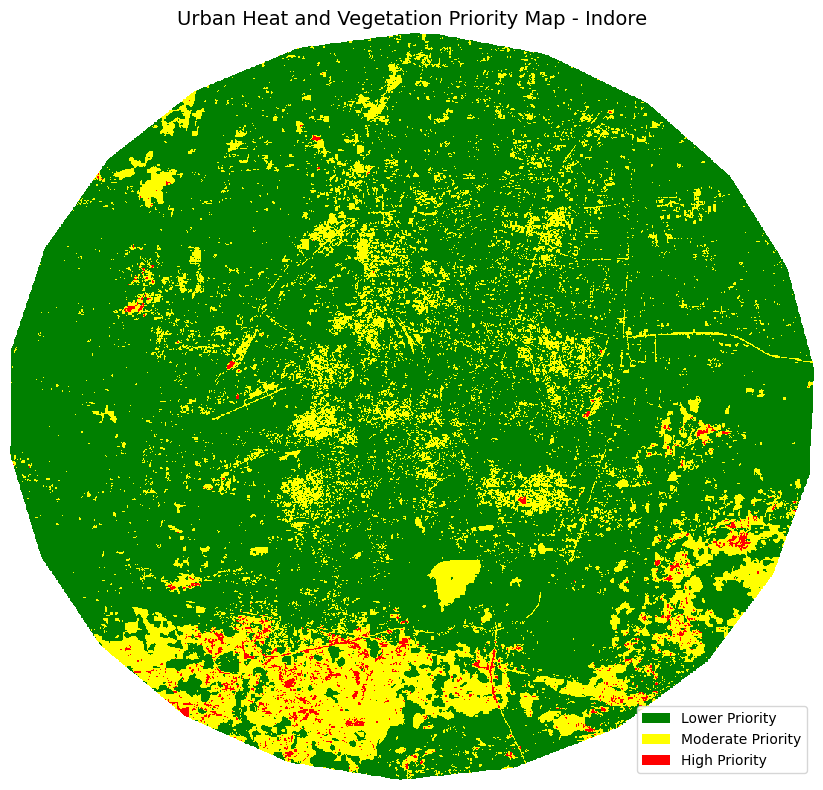

In [ ]:
# STEP 7.3: Urban heat priority map

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

priority_display = np.ma.masked_where(
    priority_map == -9999,
    priority_map
)

cmap = ListedColormap([
    'green',
    'yellow',
    'red'
])

plt.figure(figsize=(11, 8))

plt.imshow(
    priority_display,
    cmap=cmap,
    vmin=0,
    vmax=2,
    interpolation='nearest'
)

legend_items = [
    Patch(facecolor='green', label='Lower Priority'),
    Patch(facecolor='yellow', label='Moderate Priority'),
    Patch(facecolor='red', label='High Priority')
]

plt.legend(
    handles=legend_items,
    loc='lower right'
)

plt.title(
    'Urban Heat and Vegetation Priority Map - Indore',
    fontsize=14
)

plt.axis('off')
plt.tight_layout()
plt.show()

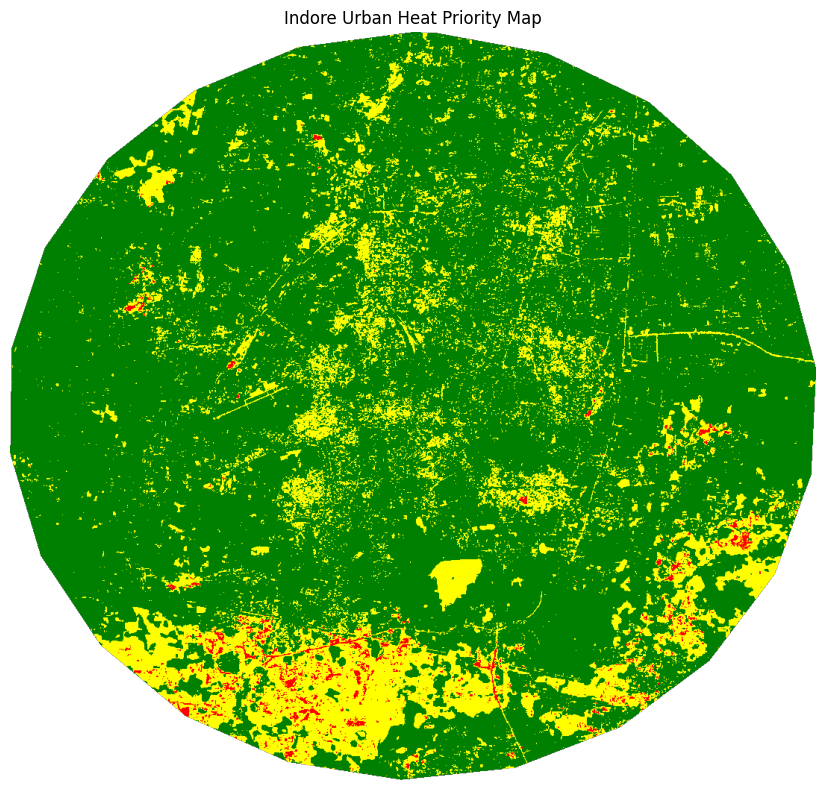

Priority GeoTIFF exported successfully!
Priority statistics saved!
Priority map PNG saved!


In [ ]:
# STEP 7.4: Export priority map as GeoTIFF

priority_tiff = os.path.join(
    output_folder,
    'Indore_Heat_Priority_Map.tif'
)

with rasterio.open(tiff_path) as src:

    profile = src.profile.copy()

    profile.update(
        count=1,
        dtype='int16',
        nodata=-9999,
        compress='lzw'
    )

    with rasterio.open(
        priority_tiff,
        'w',
        **profile
    ) as dst:

        dst.write(priority_map, 1)

# Save priority statistics

priority_summary.to_csv(
    os.path.join(
        output_folder,
        'heat_priority_summary.csv'
    ),
    index=False
)

# Save map image

plt.figure(figsize=(10, 8))

plt.imshow(
    priority_display,
    cmap=cmap,
    vmin=0,
    vmax=2
)

plt.title('Indore Urban Heat Priority Map')
plt.axis('off')
plt.tight_layout()

plt.savefig(
    os.path.join(
        output_folder,
        'Indore_Heat_Priority_Map.png'
    ),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Priority GeoTIFF exported successfully!")
print("Priority statistics saved!")
print("Priority map PNG saved!")

In [ ]:
# STEP 8A: Validate raster metadata and final statistics

# 1. Check the original GeoTIFF metadata
with rasterio.open(tiff_path) as src:
    print("===== RASTER METADATA =====")
    print("File:", os.path.basename(tiff_path))
    print("CRS:", src.crs)
    print("Dimensions:", src.width, "x", src.height)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("Number of bands:", src.count)
    print("Band descriptions:", src.descriptions)
    print("NoData value:", src.nodata)

# 2. Convert masked arrays to NumPy arrays
lst_array = np.asarray(
    np.ma.filled(lst_data, np.nan), dtype=float
)
ndvi_array = np.asarray(
    np.ma.filled(ndvi_data, np.nan), dtype=float
)

# 3. Identify valid pixels
valid = np.isfinite(lst_array) & np.isfinite(ndvi_array)

lst_valid = lst_array[valid]
ndvi_valid = ndvi_array[valid]

# 4. Calculate final temperature statistics
temperature_summary = {
    "Mean LST (C)": np.mean(lst_valid),
    "Median LST (C)": np.median(lst_valid),
    "Minimum LST (C)": np.min(lst_valid),
    "Maximum LST (C)": np.max(lst_valid),
    "10th Percentile LST (C)": np.percentile(lst_valid, 10),
    "90th Percentile LST (C)": np.percentile(lst_valid, 90),
    "Valid Pixel Count": len(lst_valid)
}

# 5. Calculate NDVI statistics
ndvi_summary = {
    "Mean NDVI": np.mean(ndvi_valid),
    "Median NDVI": np.median(ndvi_valid),
    "Minimum NDVI": np.min(ndvi_valid),
    "Maximum NDVI": np.max(ndvi_valid),
    "Valid Pixel Count": len(ndvi_valid)
}

print("\n===== TEMPERATURE STATISTICS =====")
for key, value in temperature_summary.items():
    print(f"{key}: {value:.4f}" if isinstance(value, (float, np.floating)) else f"{key}: {value}")

print("\n===== NDVI STATISTICS =====")
for key, value in ndvi_summary.items():
    print(f"{key}: {value:.4f}" if isinstance(value, (float, np.floating)) else f"{key}: {value}")

# 6. Check for unusual values
print("\n===== DATA QUALITY CHECK =====")
print("Invalid or masked paired pixels:", np.size(valid) - np.count_nonzero(valid))
print("Temperature values below 0°C:", np.count_nonzero(lst_valid < 0))
print("Temperature values above 70°C:", np.count_nonzero(lst_valid > 70))
print("NDVI values below -1:", np.count_nonzero(ndvi_valid < -1))
print("NDVI values above 1:", np.count_nonzero(ndvi_valid > 1))

===== RASTER METADATA =====
File: Indore_Heat_Analysis_2025.tif
CRS: EPSG:4326
Dimensions: 1080 x 1003
Resolution: (0.00026949458523585647, 0.00026949458523585647)
Bounds: BoundingBox(left=75.71234776533198, bottom=22.58445472652048, right=76.00340191738671, top=22.854757795512043)
Number of bands: 2
Band descriptions: ('LST_Celsius', 'NDVI')
NoData value: None

===== TEMPERATURE STATISTICS =====
Mean LST (C): 44.4441
Median LST (C): 44.2558
Minimum LST (C): 27.9621
Maximum LST (C): 57.5041
10th Percentile LST (C): 40.6908
90th Percentile LST (C): 48.6292
Valid Pixel Count: 845072

===== NDVI STATISTICS =====
Mean NDVI: 0.2638
Median NDVI: 0.2434
Minimum NDVI: -0.2194
Maximum NDVI: 0.7801
Valid Pixel Count: 845072

===== DATA QUALITY CHECK =====
Invalid or masked paired pixels: 238168
Temperature values below 0°C: 0
Temperature values above 70°C: 0
NDVI values below -1: 0
NDVI values above 1: 0


In [ ]:
# Save final statistics as CSV files

temperature_df = pd.DataFrame(
    list(temperature_summary.items()),
    columns=["Metric", "Value"]
)

ndvi_df = pd.DataFrame(
    list(ndvi_summary.items()),
    columns=["Metric", "Value"]
)

temperature_df.to_csv(
    os.path.join(output_folder, "final_temperature_statistics.csv"),
    index=False
)

ndvi_df.to_csv(
    os.path.join(output_folder, "final_ndvi_statistics.csv"),
    index=False
)

print("Final statistics exported successfully.")

Final statistics exported successfully.


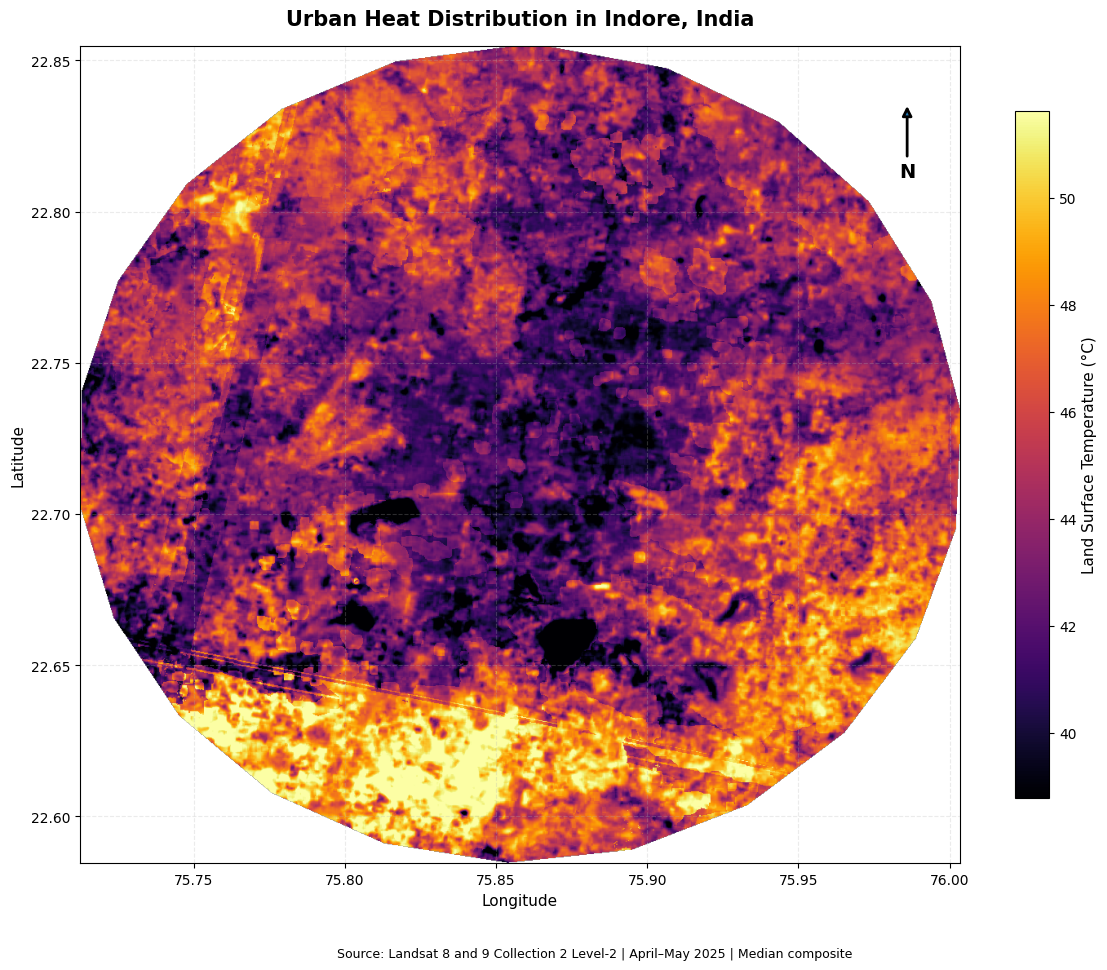

Final temperature map exported: /content/drive/MyDrive/Urban_Heat_Mapping_Project/04_Reports/Indore_Final_Temperature_Map.png


In [ ]:
# STEP 9: Professional geographic temperature map

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

# Get geographic bounds
with rasterio.open(tiff_path) as src:
    bounds = src.bounds

# Prepare temperature display
lst_display = np.ma.masked_invalid(lst_array)

fig, ax = plt.subplots(figsize=(12, 10))

image = ax.imshow(
    lst_display,
    extent=[
        bounds.left, bounds.right,
        bounds.bottom, bounds.top
    ],
    cmap="inferno",
    vmin=np.nanpercentile(lst_array, 2),
    vmax=np.nanpercentile(lst_array, 98),
    origin="upper"
)

# Colour bar
cbar = plt.colorbar(image, ax=ax, shrink=0.75)
cbar.set_label("Land Surface Temperature (°C)", fontsize=11)

# Geographic coordinates
ax.set_xlabel("Longitude", fontsize=11)
ax.set_ylabel("Latitude", fontsize=11)

ax.xaxis.set_major_locator(MaxNLocator(6))
ax.yaxis.set_major_locator(MaxNLocator(6))

# North arrow
ax.annotate(
    "N",
    xy=(0.94, 0.93),
    xytext=(0.94, 0.84),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    fontsize=14,
    fontweight="bold",
    arrowprops=dict(arrowstyle="-|>", lw=2)
)

# Title
ax.set_title(
    "Urban Heat Distribution in Indore, India",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.grid(alpha=0.25, linestyle="--")

# Source and methodology note
fig.text(
    0.5, 0.025,
    "Source: Landsat 8 and 9 Collection 2 Level-2 | "
    "April–May 2025 | Median composite",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

# Export
final_map_path = os.path.join(
    output_folder,
    "Indore_Final_Temperature_Map.png"
)

plt.savefig(
    final_map_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final temperature map exported:", final_map_path)

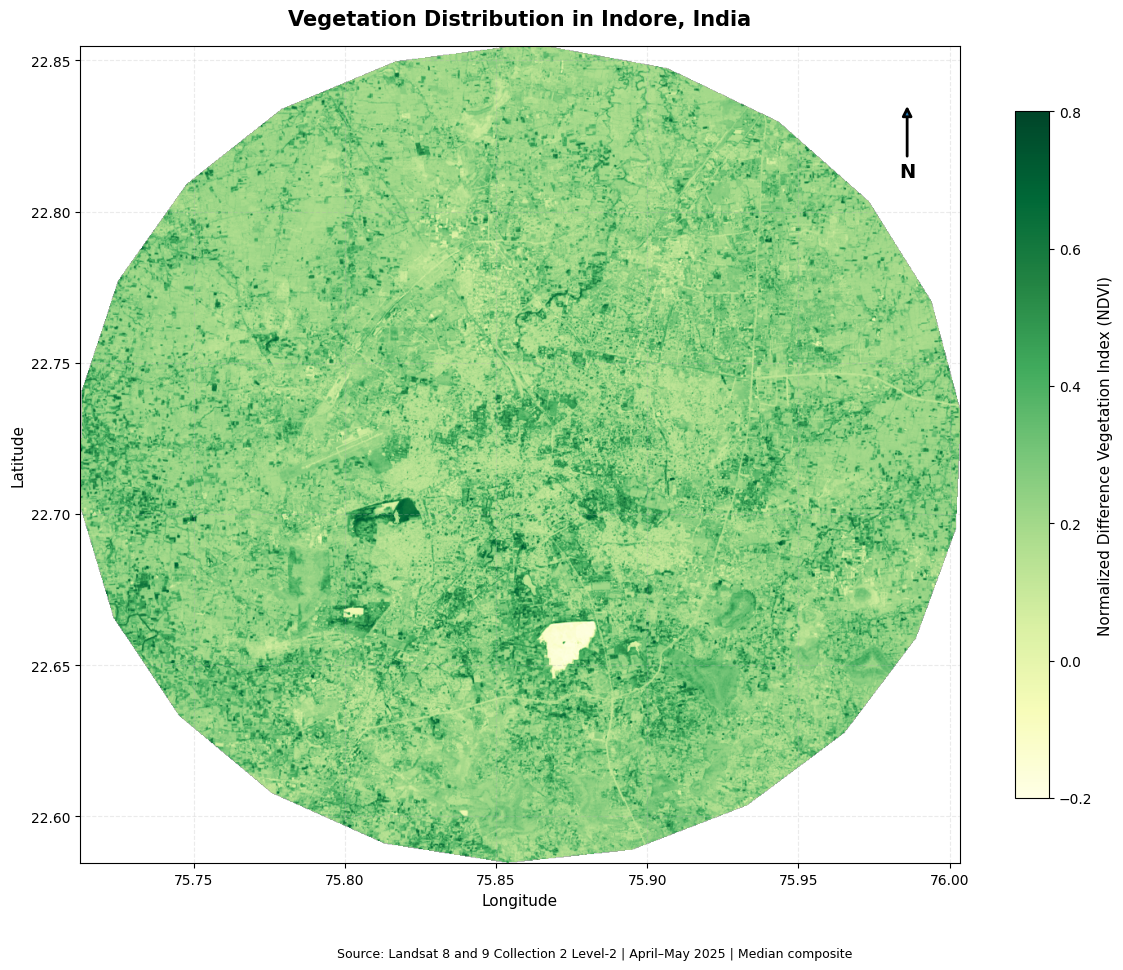

Final vegetation map exported: /content/drive/MyDrive/Urban_Heat_Mapping_Project/04_Reports/Indore_Final_Vegetation_Map.png


In [ ]:
# STEP 10: Professional NDVI Vegetation Map

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

with rasterio.open(tiff_path) as src:
    bounds = src.bounds

ndvi_display = np.ma.masked_invalid(ndvi_array)

fig, ax = plt.subplots(figsize=(12, 10))

image = ax.imshow(
    ndvi_display,
    extent=[
        bounds.left, bounds.right,
        bounds.bottom, bounds.top
    ],
    cmap="YlGn",
    vmin=-0.2,
    vmax=0.8,
    origin="upper"
)

cbar = plt.colorbar(image, ax=ax, shrink=0.75)
cbar.set_label("Normalized Difference Vegetation Index (NDVI)", fontsize=11)

ax.set_xlabel("Longitude", fontsize=11)
ax.set_ylabel("Latitude", fontsize=11)

ax.xaxis.set_major_locator(MaxNLocator(6))
ax.yaxis.set_major_locator(MaxNLocator(6))

ax.annotate(
    "N",
    xy=(0.94, 0.93),
    xytext=(0.94, 0.84),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    fontsize=14,
    fontweight="bold",
    arrowprops=dict(arrowstyle="-|>", lw=2)
)

ax.set_title(
    "Vegetation Distribution in Indore, India",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.grid(alpha=0.25, linestyle="--")

fig.text(
    0.5, 0.025,
    "Source: Landsat 8 and 9 Collection 2 Level-2 | "
    "April–May 2025 | Median composite",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

ndvi_map_path = os.path.join(
    output_folder,
    "Indore_Final_Vegetation_Map.png"
)

plt.savefig(
    ndvi_map_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final vegetation map exported:", ndvi_map_path)

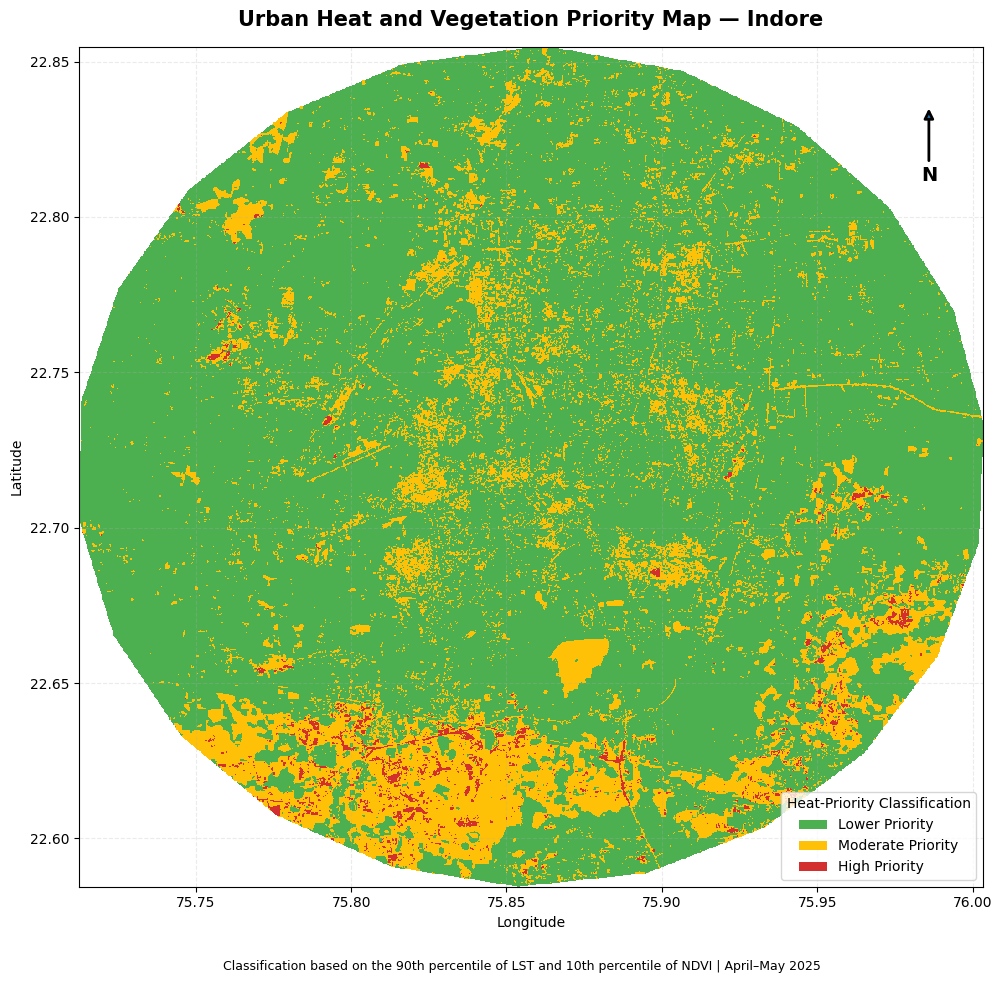

Final priority map exported: /content/drive/MyDrive/Urban_Heat_Mapping_Project/04_Reports/Indore_Final_Heat_Priority_Map.png


In [ ]:
# STEP 11: Final geographic heat-priority map

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

with rasterio.open(tiff_path) as src:
    bounds = src.bounds

priority_display = np.ma.masked_where(
    priority_map == -9999,
    priority_map
)

priority_cmap = ListedColormap([
    "#4CAF50",  # Lower priority
    "#FFC107",  # Moderate priority
    "#D32F2F"   # High priority
])

fig, ax = plt.subplots(figsize=(12, 10))

ax.imshow(
    priority_display,
    extent=[
        bounds.left, bounds.right,
        bounds.bottom, bounds.top
    ],
    cmap=priority_cmap,
    vmin=0,
    vmax=2,
    origin="upper",
    interpolation="nearest"
)

legend_items = [
    Patch(facecolor="#4CAF50", label="Lower Priority"),
    Patch(facecolor="#FFC107", label="Moderate Priority"),
    Patch(facecolor="#D32F2F", label="High Priority")
]

ax.legend(
    handles=legend_items,
    loc="lower right",
    title="Heat-Priority Classification",
    frameon=True
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.xaxis.set_major_locator(MaxNLocator(6))
ax.yaxis.set_major_locator(MaxNLocator(6))

ax.annotate(
    "N",
    xy=(0.94, 0.93),
    xytext=(0.94, 0.84),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    fontsize=14,
    fontweight="bold",
    arrowprops=dict(arrowstyle="-|>", lw=2)
)

ax.set_title(
    "Urban Heat and Vegetation Priority Map — Indore",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.grid(alpha=0.25, linestyle="--")

fig.text(
    0.5, 0.025,
    "Classification based on the 90th percentile of LST "
    "and 10th percentile of NDVI | April–May 2025",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])

final_priority_path = os.path.join(
    output_folder,
    "Indore_Final_Heat_Priority_Map.png"
)

plt.savefig(
    final_priority_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final priority map exported:", final_priority_path)

In [ ]:
print("Current output folder:", output_folder)

print("\nFiles saved in output folder:")
for file in os.listdir(output_folder):
    print(file)

Current output folder: /content/drive/MyDrive/Urban_Heat_Mapping_Project/04_Reports

Files saved in output folder:
temperature_statistics.csv
hotspot_coverage.csv
vegetation_temperature_analysis.csv
heat_priority_summary.csv
Indore_Heat_Priority_Map.tif
final_temperature_statistics.csv
final_ndvi_statistics.csv
Indore_Heat_Priority_Map.png
Indore_Final_Temperature_Map.png
Indore_Final_Vegetation_Map.png
Indore_Final_Heat_Priority_Map.png


In [ ]:
import os
import shutil

# Create the visualisation folder
visual_folder = os.path.join(
    "/content/drive/MyDrive/Urban_Heat_Mapping_Project",
    "03_Maps_Visualisations"
)

os.makedirs(visual_folder, exist_ok=True)

# Move the three final maps
map_files = [
    "Indore_Final_Temperature_Map.png",
    "Indore_Final_Vegetation_Map.png",
    "Indore_Final_Heat_Priority_Map.png"
]

for filename in map_files:
    source = os.path.join(output_folder, filename)
    destination = os.path.join(visual_folder, filename)

    if os.path.exists(source):
        shutil.move(source, destination)
        print("Moved:", filename)
    elif os.path.exists(destination):
        print("Already in visualisation folder:", filename)
    else:
        print("File not found:", filename)

print("\nVisualisation folder contents:")
for filename in os.listdir(visual_folder):
    print(filename)

Moved: Indore_Final_Temperature_Map.png
Moved: Indore_Final_Vegetation_Map.png
Moved: Indore_Final_Heat_Priority_Map.png

Visualisation folder contents:
Indore_Final_Heat_Priority_Map.png
Indore_Final_Vegetation_Map.png
Indore_Final_Temperature_Map.png


In [ ]:
import pandas as pd
import os

for filename in [
    "final_temperature_statistics.csv",
    "final_ndvi_statistics.csv",
    "heat_priority_summary.csv",
    "vegetation_temperature_analysis.csv",
    "hotspot_coverage.csv"
]:
    path = os.path.join(output_folder, filename)

    if os.path.exists(path):
        print("\n==========", filename, "==========")
        display(pd.read_csv(path))


========== final_temperature_statistics.csv ==========


,Metric,Value
0,Mean LST (C),44.444093
1,Median LST (C),44.255844
2,Minimum LST (C),27.962145
3,Maximum LST (C),57.504089
4,10th Percentile LST (C),40.690849
5,90th Percentile LST (C),48.629204
6,Valid Pixel Count,845072.000000



========== final_ndvi_statistics.csv ==========


,Metric,Value
0,Mean NDVI,0.263785
1,Median NDVI,0.243430
2,Minimum NDVI,-0.219396
3,Maximum NDVI,0.780150
4,Valid Pixel Count,845072.000000



========== heat_priority_summary.csv ==========


,Priority,Pixel Count,Percentage
0,Lower Priority,685258,81.088712
1,Moderate Priority,150580,17.818600
2,High Priority,9234,1.092688



========== vegetation_temperature_analysis.csv ==========


,Metric,Value
0,Pearson Correlation,-0.191031
1,P-value,0.000000
2,Mean NDVI in Hotspots,0.240755
3,Mean NDVI Outside Hotspots,0.266345
4,Valid Paired Pixels,845072.000000



========== hotspot_coverage.csv ==========


,Category,Pixel Count,Percentage
0,Relative Hotspots,84540,7.804365
1,Other Areas,998700,92.195635


In [29]:
# Correct hotspot coverage using valid paired pixels

valid = np.isfinite(lst_array) & np.isfinite(ndvi_array)

hotspot_threshold = np.nanpercentile(
    lst_array[valid], 90
)

hotspot_mask = (
    valid & (lst_array >= hotspot_threshold)
)

hotspot_count = np.count_nonzero(hotspot_mask)
valid_count = np.count_nonzero(valid)

other_count = valid_count - hotspot_count

corrected_hotspot_summary = pd.DataFrame([
    {
        "Category": "Relative Hotspots",
        "Pixel Count": hotspot_count,
        "Percentage": hotspot_count / valid_count * 100
    },
    {
        "Category": "Other Areas",
        "Pixel Count": other_count,
        "Percentage": other_count / valid_count * 100
    }
])

corrected_hotspot_summary.to_csv(
    os.path.join(output_folder, "hotspot_coverage.csv"),
    index=False
)

display(corrected_hotspot_summary)

print("Corrected hotspot statistics saved.")

,Category,Pixel Count,Percentage
0,Relative Hotspots,84540,10.003881
1,Other Areas,760532,89.996119


Corrected hotspot statistics saved.
